# Prior clinical knoeledge via confounder decetion

This notebook reproduces the third step of pipeline described in: *"Enhancing comorbidity network inference with risk-enriched health trajectories embedding"*
Going through the following steps:
1. Differential similarity matrix construction
2. Statistical evaluation of the differential matrix
3. Confounding detection and validation
4. Confounder selection as prior clinical knowledge 

## Section 0 — Data Import and helper functions

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import networkx as nx
from scipy.spatial.distance import cosine
from scipy.stats import mannwhitneyu, pearsonr, spearmanr, wilcoxon, ks_2samp
from scipy.special import erfc
from sklearn.covariance import GraphicalLassoCV
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120})

# Output directories
OUTPUT_RES_DIR   = "results"
OUTPUT_PLOTS_DIR = "plots"
os.makedirs(OUTPUT_RES_DIR,   exist_ok=True)
os.makedirs(OUTPUT_PLOTS_DIR, exist_ok=True)

In [2]:
sequence_main_final = pd.read_csv(os.path.join(OUTPUT_RES_DIR,'sequence_main_final.csv'))
sequence_par_final = pd.read_csv(os.path.join(OUTPUT_RES_DIR,'sequence_par_final.csv'))
sequence_main_par_final =  pd.read_csv(os.path.join(OUTPUT_RES_DIR,'sequence_main_par_final.csv'))

In [ ]:
DISEASE_NAMES_MAIN = sorted([n for n in sequence_main_final["event_name"].unique()])
RF_NAMES=sorted([n for n in sequence_par_final["event_name"].unique()])
EVENTS_NAMES = DISEASE_NAMES_MAIN + RF_NAMES

In [4]:
cardiomet_embeddings = pd.read_csv(os.path.join(OUTPUT_RES_DIR,"cardiomet_embeddings.csv"))
cardiomet_risk_adj_embeddings = pd.read_csv(os.path.join(OUTPUT_RES_DIR,"cardiomet_risk_adj_embeddings.csv"))

In [5]:
def plot_sim_heatmap(df: pd.DataFrame, title: str, fname: str,
                     vmin: float = None, vmax: float = None,
                     cmap: str = "Blues") -> None:
    """Lower-triangle seaborn heatmap for a square similarity matrix."""
    mask = np.triu(np.ones(df.shape, dtype=bool), k=0)
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(df, mask=mask, cmap=cmap, annot=False, square=True,
                linewidths=0.3, cbar_kws={"shrink": 0.8},
                vmin=vmin, vmax=vmax, ax=ax)
    ax.set_title(title, fontsize=13)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(fname, format="svg", bbox_inches="tight")
    plt.savefig(fname.replace(".svg", ".pdf"),
                bbox_inches="tight")
    plt.show()

## Section 1 — Differential similarity matrix construction

### 1.1  Construct the similarity matrices from the cardiometabolic and the cardiomatabolic risk-adjusted embeddings

In [6]:
similarity_matrix_main = np.zeros((len(DISEASE_NAMES_MAIN), len(DISEASE_NAMES_MAIN)))
for i, event_i in enumerate(DISEASE_NAMES_MAIN):
    for j, event_j in enumerate(DISEASE_NAMES_MAIN):
        vec_i = cardiomet_embeddings[event_i].values
        vec_j = cardiomet_embeddings[event_j].values
        # Cosine similarity
        similarity = 1 - cosine(vec_i, vec_j)
        similarity_matrix_main[i, j] = similarity
sim_main_df  = pd.DataFrame(similarity_matrix_main,
                             index=DISEASE_NAMES_MAIN,
                             columns=DISEASE_NAMES_MAIN)

similarity_matrix_mainpar = np.zeros((len(EVENTS_NAMES), len(EVENTS_NAMES)))
for i, event_i in enumerate(EVENTS_NAMES):
    for j, event_j in enumerate(EVENTS_NAMES):
        vec_i = cardiomet_risk_adj_embeddings[event_i].values
        vec_j = cardiomet_risk_adj_embeddings[event_j].values
        # Cosine similarity
        similarity = 1 - cosine(vec_i, vec_j)
        similarity_matrix_mainpar[i, j] = similarity
sim_mainpar_all_df  = pd.DataFrame(similarity_matrix_mainpar,
                             index=EVENTS_NAMES,
                             columns=EVENTS_NAMES)

sim_mainpar_df = sim_mainpar_all_df.loc[DISEASE_NAMES_MAIN, DISEASE_NAMES_MAIN]

_vals  = np.concatenate([sim_main_df.values.flatten(),
                          sim_mainpar_df.values.flatten()])
VMIN_SIM = float(np.min(_vals))
VMAX_SIM = float(np.max(_vals))

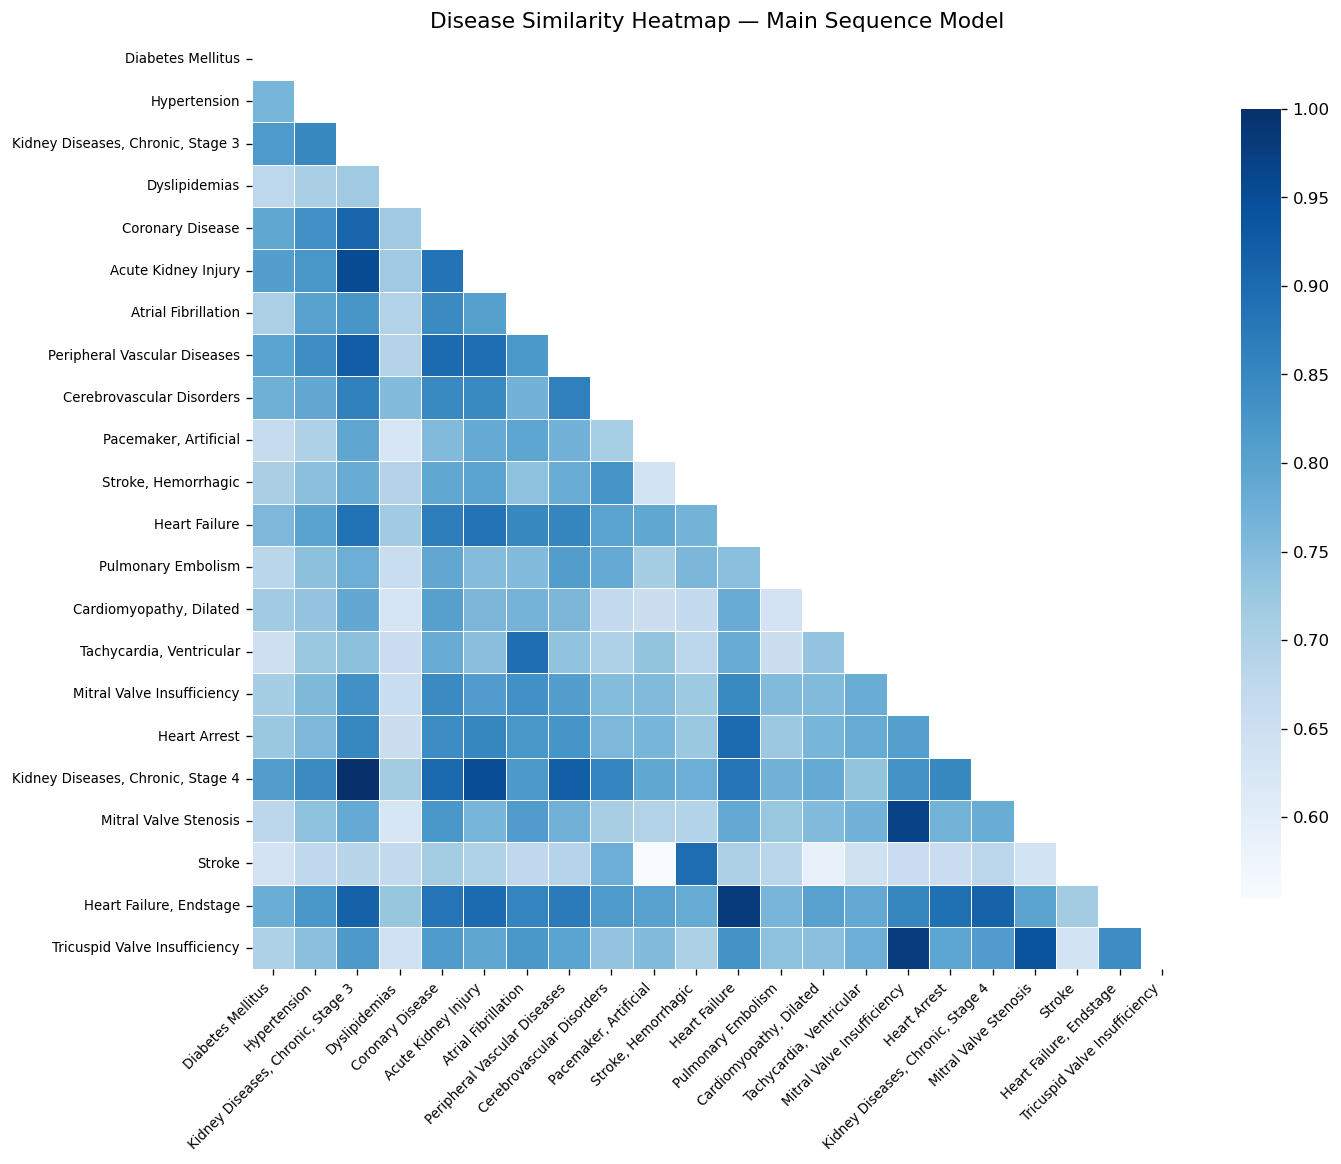

In [7]:
plot_sim_heatmap(sim_main_df,
                 "Disease Similarity Heatmap — Main Sequence Model",
                 os.path.join(OUTPUT_PLOTS_DIR,"disease_similarity_heatmap_main.svg"),
                 vmin=VMIN_SIM, vmax=VMAX_SIM)

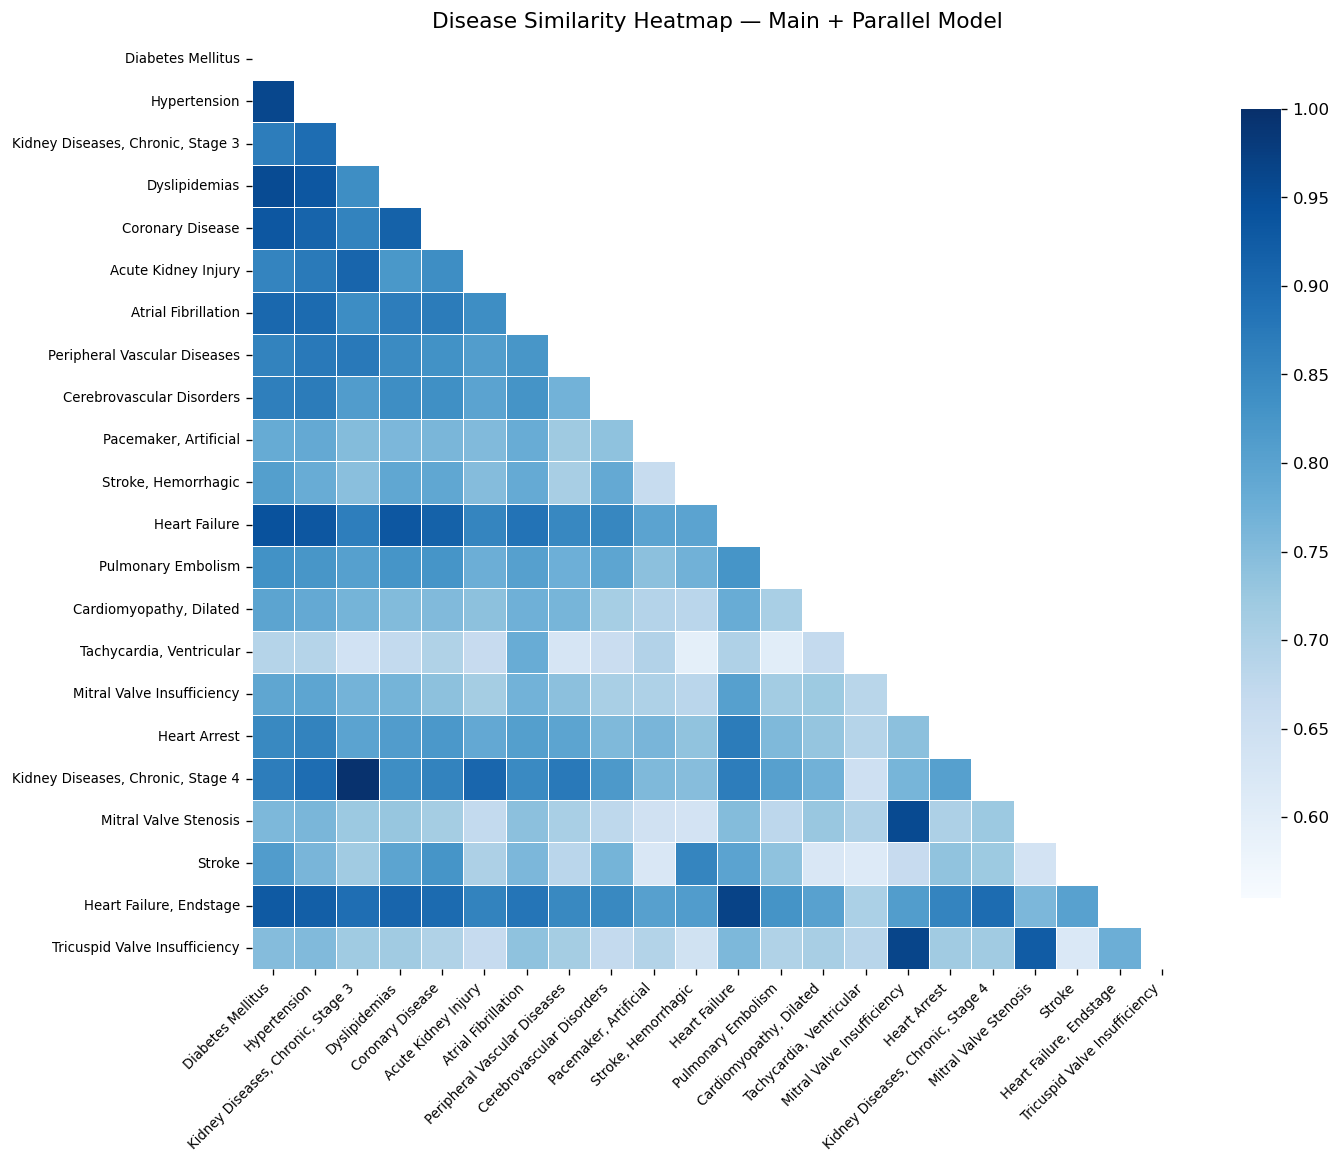

In [8]:
plot_sim_heatmap(sim_mainpar_df,
                 "Disease Similarity Heatmap — Main + Parallel Model",
                 os.path.join(OUTPUT_PLOTS_DIR,"disease_similarity_heatmap_main_par.svg"),
                 vmin=VMIN_SIM, vmax=VMAX_SIM)

### 1.2  Differential similarity matrices

In [9]:
# Also create the signed difference for directional analysis
similarity_df_diff_signed = pd.DataFrame(sim_mainpar_df.values - similarity_matrix_main, 
                                        index=DISEASE_NAMES_MAIN, columns=DISEASE_NAMES_MAIN)
similarity_df_diff = pd.DataFrame(abs(sim_mainpar_df.values  - similarity_matrix_main), 
                                 index=DISEASE_NAMES_MAIN, columns=DISEASE_NAMES_MAIN)

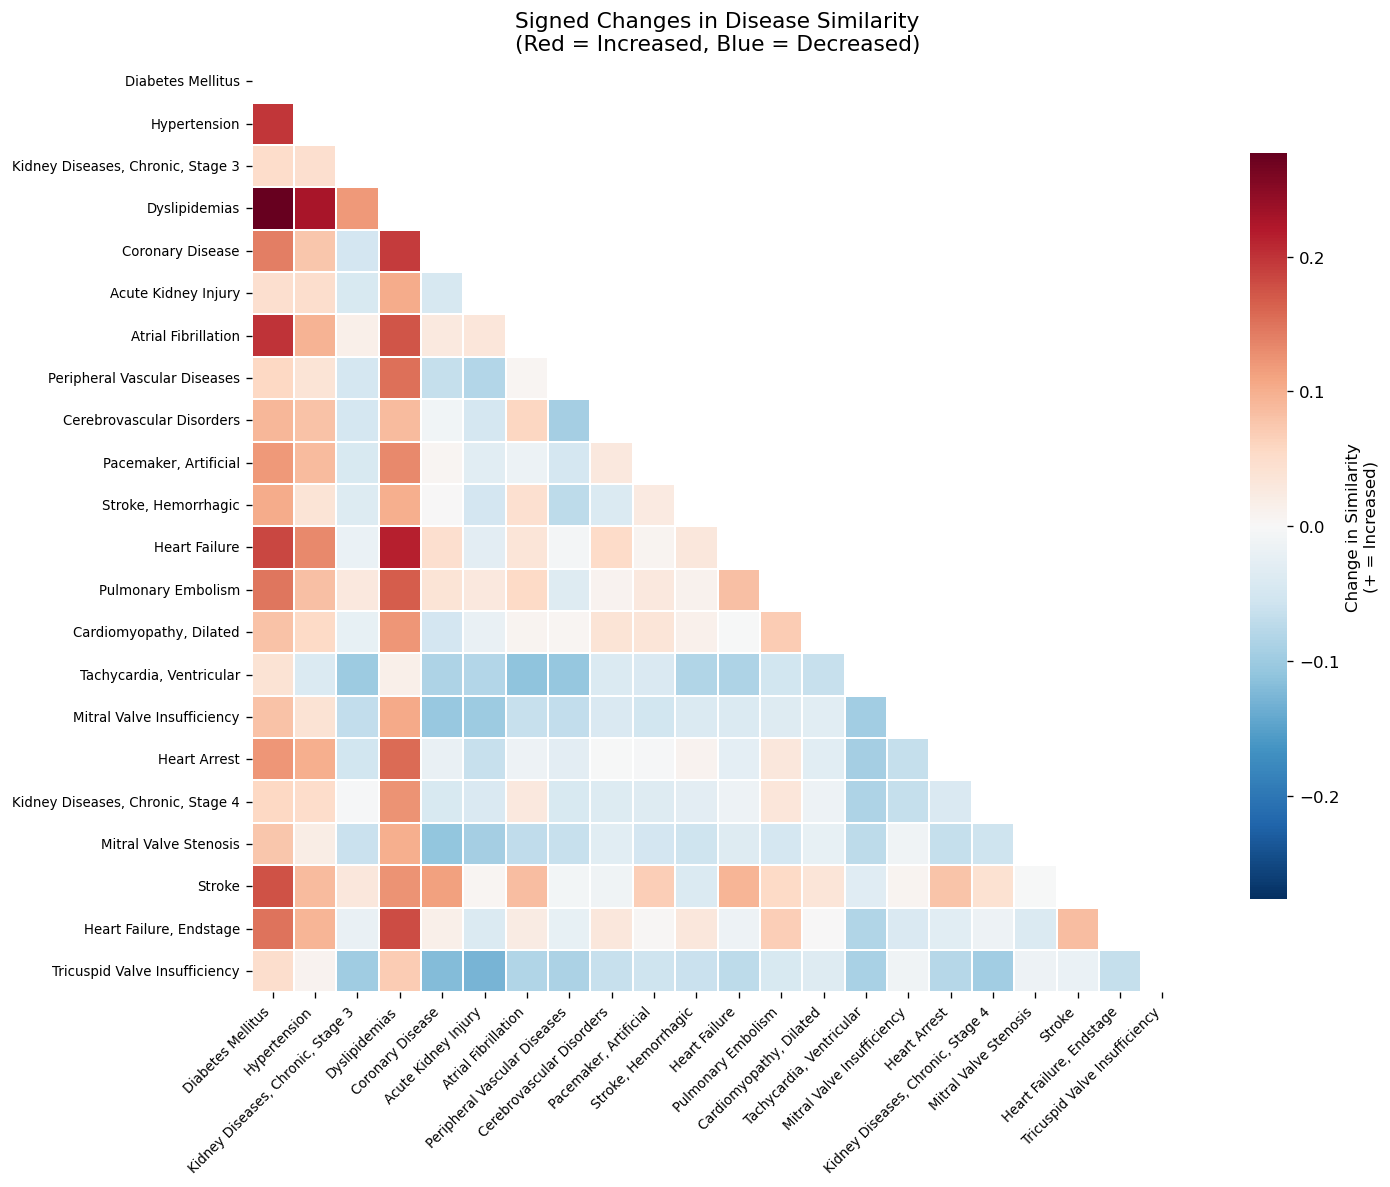

In [10]:
mask_tri = np.triu(np.ones(similarity_df_diff_signed.shape, dtype=bool), k=0)
fig, ax  = plt.subplots(figsize=(13, 10))
vmax_d   = float(np.nanmax(np.abs(similarity_df_diff_signed.values)))
sns.heatmap(similarity_df_diff_signed, mask=mask_tri, cmap="RdBu_r", center=0,
            vmin=-vmax_d, vmax=vmax_d, annot=False, square=True,
            linewidths=0.1, cbar_kws={"shrink": 0.8,
                                       "label": "Change in Similarity\n(+ = Increased)"},
            ax=ax)
ax.set_title("Signed Changes in Disease Similarity\n(Red = Increased, Blue = Decreased)",
             fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_similarity_changes_signed.svg"),
            format="svg", bbox_inches="tight")
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_similarity_changes_signed.pdf"),
            bbox_inches="tight")
plt.show()

## Section 2 - Statistical evaluation of the differential matrix

### 2.1  Matrix-level comparison statistics

In [11]:
print("\n1. MATRIX-LEVEL STATISTICS")
print("-" * 30)

# Get upper triangular values (excluding diagonal)
mask = np.triu(np.ones_like(sim_mainpar_df.values, dtype=bool), k=1)
orig_values = sim_main_df.values[mask]
modified_values = sim_mainpar_df.values[mask]
diff_values = similarity_df_diff_signed.values[mask]

# Basic difference statistics
mad = np.mean(np.abs(diff_values))
rmsd = np.sqrt(np.mean(diff_values**2))
max_change = np.max(np.abs(diff_values))
mean_change = np.mean(diff_values)
std_change = np.std(diff_values)

print(f"Mean Absolute Difference (MAD): {mad:.4f}")
print(f"Root Mean Square Difference (RMSD): {rmsd:.4f}")
print(f"Maximum Change: {max_change:.4f}")
print(f"Mean Change (directional): {mean_change:.4f}")
print(f"Standard Deviation of Changes: {std_change:.4f}")

# Percentage of relationships affected at different thresholds
thresh_001 = np.sum(np.abs(diff_values) > 0.01) / len(diff_values) * 100
thresh_005 = np.sum(np.abs(diff_values) > 0.05) / len(diff_values) * 100
thresh_010 = np.sum(np.abs(diff_values) > 0.10) / len(diff_values) * 100

print(f"\nPercentage of disease pairs affected:")
print(f"  >1% change: {thresh_001:.1f}%")
print(f"  >5% change: {thresh_005:.1f}%")
print(f"  >10% change: {thresh_010:.1f}%")


1. MATRIX-LEVEL STATISTICS
------------------------------
Mean Absolute Difference (MAD): 0.0615
Root Mean Square Difference (RMSD): 0.0773
Maximum Change: 0.2765
Mean Change (directional): 0.0092
Standard Deviation of Changes: 0.0767

Percentage of disease pairs affected:
  >1% change: 91.8%
  >5% change: 48.9%
  >10% change: 16.9%


### 2.2  Correlation analysis

In [12]:
print("\n2. CORRELATION ANALYSIS")
print("-" * 25)

# Correlation between original and modified matrices
pearson_r, pearson_p = pearsonr(orig_values, modified_values)
spearman_r, spearman_p = spearmanr(orig_values, modified_values)

print(f"Pearson correlation: {pearson_r:.4f} (p={pearson_p:.2e})")
print(f"Spearman rank correlation: {spearman_r:.4f} (p={spearman_p:.2e})")

# Interpretation
if pearson_r > 0.9:
    interpretation = "Excellent preservation - minimal confounding detected"
elif pearson_r > 0.7:
    interpretation = "Good preservation - moderate confounding effects"
elif pearson_r > 0.5:
    interpretation = "Fair preservation - substantial confounding detected"
else:
    interpretation = "Poor preservation - major structural changes"

print(f"Interpretation: {interpretation}")



2. CORRELATION ANALYSIS
-------------------------
Pearson correlation: 0.5524 (p=7.43e-20)
Spearman rank correlation: 0.5100 (p=1.07e-16)
Interpretation: Fair preservation - substantial confounding detected


### 2.3  Statistical significance testing

In [13]:
print("\n3. STATISTICAL SIGNIFICANCE")
print("-" * 28)

# Test if changes are systematically different from zero
statistic, p_value = wilcoxon(diff_values, alternative='two-sided')
print(f"Wilcoxon test for systematic change: p={p_value:.2e}")

if p_value < 0.001:
    print("Highly significant systematic changes detected")
elif p_value < 0.05:
    print("Significant systematic changes detected")
else:
    print("No systematic changes detected")

# Distribution comparison
ks_stat, ks_p = ks_2samp(orig_values, modified_values)
print(f"Kolmogorov-Smirnov test: KS={ks_stat:.4f}, p={ks_p:.2e}")


3. STATISTICAL SIGNIFICANCE
----------------------------
Wilcoxon test for systematic change: p=5.18e-01
No systematic changes detected
Kolmogorov-Smirnov test: KS=0.0909, p=2.96e-01


### 2.4  Disease pair classification

In [14]:
# Find pairs with largest changes
diff_matrix = similarity_df_diff_signed.values
np.fill_diagonal(diff_matrix, 0)  # Remove diagonal

# Get indices of largest changes
flat_indices = np.argsort(np.abs(diff_matrix.flatten()))[::-1]
row_indices, col_indices = np.unravel_index(flat_indices, diff_matrix.shape)
change_vec = []
seen_pairs = set()
results = []
count = 0

for i in range(len(flat_indices)):
    r, c = row_indices[i], col_indices[i]
    if r != c:
        # Avoid duplicate pairs (r,c) and (c,r)
        pair = tuple(sorted([r, c]))
        if pair not in seen_pairs:
            change = diff_matrix[r, c]
            change_vec.append(change)
            direction = "Increased" if change > 0 else "Decreased"
            disease1 = DISEASE_NAMES_MAIN[r]
            disease2 = DISEASE_NAMES_MAIN[c]
            
            results.append({
                "rank": count + 1,
                "disease1": disease1,
                "disease2": disease2,
                "change": change,
                "direction": direction
            })
            seen_pairs.add(pair)
            count += 1   

top_changes_df = pd.DataFrame(results)

95th percentile: 0.15473578241031494


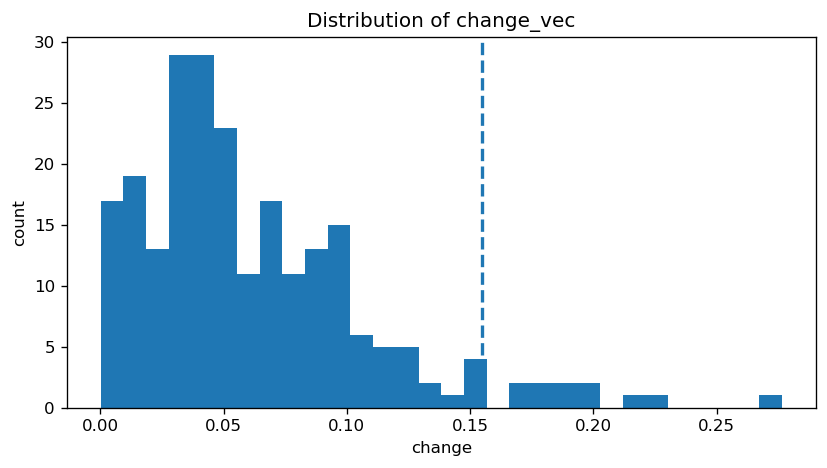

Number above the 95th percentile: 12


In [15]:
x = np.asarray(np.abs(change_vec), dtype=float)
x = x[~np.isnan(x)]
p95 = np.percentile(x, 95)
print("95th percentile:", p95)

plt.figure(figsize=(7, 4))
plt.hist(x, bins=30)
plt.axvline(p95, linestyle="--", linewidth=2)
plt.title("Distribution of change_vec")
plt.xlabel("change")
plt.ylabel("count")
plt.tight_layout()
plt.show()

n_above = np.sum(x > p95)
print("Number above the 95th percentile:", n_above)

In [16]:
print("\n4. MOST AFFECTED DISEASE PAIRS")
print("-" * 30)
top_changes_df.head(n_above)


4. MOST AFFECTED DISEASE PAIRS
------------------------------


,rank,disease1,disease2,change,direction
0,1,Dyslipidemias,Diabetes Mellitus,0.276452,Increased
1,2,Hypertension,Dyslipidemias,0.227270,Increased
2,3,Dyslipidemias,Heart Failure,0.214443,Increased
3,4,Atrial Fibrillation,Diabetes Mellitus,0.200633,Increased
4,5,Hypertension,Diabetes Mellitus,0.198168,Increased
5,6,Coronary Disease,Dyslipidemias,0.192852,Increased
6,7,Diabetes Mellitus,Heart Failure,0.185152,Increased
7,8,"Heart Failure, Endstage",Dyslipidemias,0.180173,Increased
8,9,Stroke,Diabetes Mellitus,0.175874,Increased
9,10,Dyslipidemias,Atrial Fibrillation,0.174369,Increased


## Section 3 -  Confounding detection and validation

Adjust the `RF_CORRELATION_THRESHOLD` and `TOP_N_PAIRS` parameters below before running the fine-tuning cells.

> * `RF_CORRELATION_THRESHOLD`: minimum cosine similarity between a risk factor and a disease to consider the risk factor "highly correlated" with that disease.
>   **Default = median of the risk-factor × risk-factor similarity submatrix** (mirrors
>   the criterion used in the original analysis).
> * `TOP_N_PAIRS`: number of most-affected disease pairs to highlight in the analysis. **Default = those presenting a change higher then the 95-th percentail of overall changes**
>
>   Note: Sensitivity analysis below lets you explore multiple `RF_CORRELATION_THRESHOLD` automatically.


In [17]:
# Risk-factor × risk-factor similarity submatrix 
sim_rf_rf = sim_mainpar_all_df.loc[RF_NAMES, RF_NAMES].values

RF_CORRELATION_THRESHOLD = float(np.median(sim_rf_rf))  # override if desired
TOP_N_PAIRS              = n_above   # number of top affected disease pairs

print(f"RF correlation threshold (median): {RF_CORRELATION_THRESHOLD:.4f}")
print(f"Top N pairs to analyse:            {TOP_N_PAIRS}")

RF correlation threshold (median): 0.8477
Top N pairs to analyse:            12


### 3.1  Risk factor definition

In [18]:
top_affected_pairs = top_changes_df.head(TOP_N_PAIRS).reset_index(drop=True)
# Extract unique diseases from these pairs
unique_diseases = list(set(top_affected_pairs["disease1"]) | set(top_affected_pairs["disease2"]))

In [19]:
def analyze_disease_risk_correlations(diseases, risk_factors, similarity_df, threshold=0.5, verbose=False):
    """
    Find risk factors highly correlated with each disease
    """
    if verbose:
        print(f"\nAnalyzing correlations for {len(diseases)} diseases...")
        print(f"Using correlation threshold: {threshold}")
        print(f"Available risk factors: {len(risk_factors)}")
    
    disease_risk_correlations = {}
    
    for disease in diseases:
        if verbose:
            print(f"\n--- Analyzing {disease} ---")      
        if disease in similarity_df.index:
            correlations = []          
            for rf in risk_factors:
                if rf in similarity_df.columns:
                    correlation = similarity_df.loc[disease, rf]
                    
                    if correlation >= threshold:
                        correlations.append({
                            'risk_factor': rf,
                            'correlation': correlation
                        })
            correlations.sort(key=lambda x: x['correlation'], reverse=True)
            disease_risk_correlations[disease] = correlations
            
            if verbose:
                print(f"High correlations found (≥{threshold}): {len(correlations)}")
                if correlations:
                    print("Top risk factor correlations:")
                    for corr in correlations[:5]:  # Show top 5
                        print(f"  • {corr['risk_factor']}: {corr['correlation']:.3f}")
                else:
                    print(f"  • No risk factors above threshold {threshold}")

        else:
            if verbpse:
                print(f"  • WARNING: {disease} not found in phrases_main_par")
            disease_risk_correlations[disease] = []
    
    return disease_risk_correlations

In [20]:
disease_correlations = analyze_disease_risk_correlations(
    unique_diseases, RF_NAMES, sim_mainpar_all_df, threshold=RF_CORRELATION_THRESHOLD, verbose = True
)


Analyzing correlations for 10 diseases...
Using correlation threshold: 0.847650951962914
Available risk factors: 81

--- Analyzing Dyslipidemias ---
High correlations found (≥0.847650951962914): 46
Top risk factor correlations:
  • Heart Rate, Low: 0.955
  • Heart Rate, High: 0.953
  • White Blood Cell Count, High: 0.952
  • HbA1c, High: 0.948
  • White Blood Cell Count, Normal: 0.948

--- Analyzing Heart Failure, Endstage ---
High correlations found (≥0.847650951962914): 48
Top risk factor correlations:
  • Heart Rate, High: 0.951
  • Heart Rate, Low: 0.950
  • Heart Rate, Normal: 0.949
  • White Blood Cell Count, High: 0.939
  • BNP, High: 0.938

--- Analyzing Pulmonary Embolism ---
High correlations found (≥0.847650951962914): 18
Top risk factor correlations:
  • Chronic Obstructive Pulmonary Disease: 0.874
  • Diastolic Blood Pressure, Normal: 0.858
  • Systolic Blood Pressure, Normal: 0.857
  • HbA1c, Normal: 0.856
  • Heart Rate, Normal: 0.856

--- Analyzing Heart Failure ---
Hi

### 3.2  Confounder detection

In [21]:
def analyze_pair_shared_risk_factors(pair, disease_correlations):
    disease1 = pair['disease1']
    disease2 = pair['disease2']
    change = pair["change"]
    
    rf1 = disease_correlations.get(disease1, [])
    rf2 = disease_correlations.get(disease2, [])
    
    rf1_names = {corr['risk_factor'] for corr in rf1}
    rf2_names = {corr['risk_factor'] for corr in rf2}
    
    shared_rf = rf1_names.intersection(rf2_names)

    return {
        'pair': f"{disease1} ↔ {disease2}",
        'n_rf_disease1': len(rf1),
        'n_rf_disease2': len(rf2),
        'n_shared': len(shared_rf),
        'normalized_shared': len(shared_rf) / min(len(rf1), len(rf2)) if min(len(rf1), len(rf2)) > 0 else 0,
        'change': similarity_df_diff_signed.loc[disease1,disease2 ]
    }

In [22]:
pair_analyses = [
    analyze_pair_shared_risk_factors(row, disease_correlations)
    for _, row in top_affected_pairs.iterrows()
]

pair_analyses_df = pd.DataFrame(pair_analyses)
pair_analyses_df

,pair,n_rf_disease1,n_rf_disease2,n_shared,normalized_shared,change
0,Dyslipidemias ↔ Diabetes Mellitus,46,54,46,1.000000,0.276452
1,Hypertension ↔ Dyslipidemias,49,46,43,0.934783,0.227270
2,Dyslipidemias ↔ Heart Failure,46,51,46,1.000000,0.214443
3,Atrial Fibrillation ↔ Diabetes Mellitus,43,54,43,1.000000,0.200633
4,Hypertension ↔ Diabetes Mellitus,49,54,48,0.979592,0.198168
5,Coronary Disease ↔ Dyslipidemias,51,46,46,1.000000,0.192852
6,Diabetes Mellitus ↔ Heart Failure,54,51,50,0.980392,0.185152
7,"Heart Failure, Endstage ↔ Dyslipidemias",48,46,46,1.000000,0.180173
8,Stroke ↔ Diabetes Mellitus,9,54,9,1.000000,0.175874
9,Dyslipidemias ↔ Atrial Fibrillation,46,43,43,1.000000,0.174369


### 3.3 Sensitivity analysis

In [23]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

correlation_threshold_vec = [0.5, 0.6, 0.70, 0.72, 0.8, 0.9]  # or more thresholds if you like, e.g. [0.70, 0.73, 0.75]

all_results = None  # final wide table: pair + normalized_shared per threshold

for t in correlation_threshold_vec:
    temp_disease_correlations = analyze_disease_risk_correlations(
    DISEASE_NAMES_MAIN, RF_NAMES, sim_mainpar_all_df, threshold=t)
    
    pair_analyses_temp = [
        analyze_pair_shared_risk_factors(row, temp_disease_correlations)
        for _, row in top_changes_df.iterrows()  # or whatever list of pairs you use
    ]

    df_results_temp = pd.DataFrame(pair_analyses_temp)

    # keep only pair + normalized_shared
    df_results_temp = df_results_temp[['pair', 'normalized_shared']]

    # rename normalized_shared column to the threshold value
    col_name = f"{t}"
    df_results_temp = df_results_temp.rename(columns={'normalized_shared': col_name})

    # merge into wide table
    if all_results is None:
        all_results = df_results_temp
    else:
        all_results = all_results.merge(df_results_temp, on='pair', how='outer')

    # (optional) print summary stats per threshold
    mean_val = df_results_temp[col_name].mean()
    sd_val   = df_results_temp[col_name].std()
    print(f"Threshold {t}")
    print(f"  mean normalized_shared = {mean_val:.4f}")
    print(f"  sd   normalized_shared = {sd_val:.4f}\n")

Threshold 0.5
  mean normalized_shared = 1.0000
  sd   normalized_shared = 0.0000

Threshold 0.6
  mean normalized_shared = 0.9977
  sd   normalized_shared = 0.0061

Threshold 0.7
  mean normalized_shared = 0.9970
  sd   normalized_shared = 0.0101

Threshold 0.72
  mean normalized_shared = 0.9929
  sd   normalized_shared = 0.0231

Threshold 0.8
  mean normalized_shared = 0.6966
  sd   normalized_shared = 0.4379

Threshold 0.9
  mean normalized_shared = 0.1726
  sd   normalized_shared = 0.3647



##### Test the following hypothesis: higher the change, higher the percentage od confounder detected

In [24]:
for t in correlation_threshold_vec:
    col_name = f"{t}"
    group_top = all_results[col_name].iloc[:TOP_N_PAIRS].dropna()
    group_rest = all_results[col_name].iloc[TOP_N_PAIRS:].dropna()
    
    if len(group_top) == 0 or len(group_rest) == 0:
        print(f"Threshold {t}: not enough data for Wilcoxon test.")
        continue
        
    stat, p_value = mannwhitneyu(group_top, group_rest, alternative='greater')

    print(f"Threshold {t}: Wilcoxon rank-sum p-value (first {TOP_N_PAIRS} vs others) = {p_value:.4g}")

all_results_top = all_results.iloc[:TOP_N_PAIRS].copy()
all_results_top.head(14)

Threshold 0.5: Wilcoxon rank-sum p-value (first 12 vs others) = 1
Threshold 0.6: Wilcoxon rank-sum p-value (first 12 vs others) = 0.8073
Threshold 0.7: Wilcoxon rank-sum p-value (first 12 vs others) = 0.09953
Threshold 0.72: Wilcoxon rank-sum p-value (first 12 vs others) = 0.2588
Threshold 0.8: Wilcoxon rank-sum p-value (first 12 vs others) = 0.004622
Threshold 0.9: Wilcoxon rank-sum p-value (first 12 vs others) = 9.064e-08


,pair,0.5,0.6,0.7,0.72,0.8,0.9
0,Dyslipidemias ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,1.00,1.000000
1,Hypertension ↔ Dyslipidemias,1.0,0.987342,1.0,1.000000,1.00,0.903226
2,Dyslipidemias ↔ Heart Failure,1.0,0.987342,1.0,1.000000,1.00,1.000000
3,Atrial Fibrillation ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,1.00,1.000000
4,Hypertension ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,1.00,0.948718
5,Coronary Disease ↔ Dyslipidemias,1.0,1.000000,1.0,1.000000,1.00,0.870968
6,Diabetes Mellitus ↔ Heart Failure,1.0,1.000000,1.0,1.000000,1.00,1.000000
7,"Heart Failure, Endstage ↔ Dyslipidemias",1.0,1.000000,1.0,1.000000,1.00,0.967742
8,Stroke ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,0.95,0.000000
9,Dyslipidemias ↔ Atrial Fibrillation,1.0,0.987342,1.0,1.000000,1.00,1.000000


## Important check for the code

In [25]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

correlation_threshold_vec = [0.5, 0.6, 0.70, 0.72, 0.8, 0.9]  # or more thresholds if you like, e.g. [0.70, 0.73, 0.75]

all_results = None  # final wide table: pair + normalized_shared per threshold

for t in correlation_threshold_vec:
    temp_disease_correlations = analyze_disease_risk_correlations(
    unique_diseases, RF_NAMES, sim_mainpar_all_df, threshold=t)
    
    pair_analyses_temp = [
        analyze_pair_shared_risk_factors(row, temp_disease_correlations)
        for _, row in top_changes_df.iterrows()  # or whatever list of pairs you use
    ]

    df_results_temp = pd.DataFrame(pair_analyses_temp)

    # keep only pair + normalized_shared
    df_results_temp = df_results_temp[['pair', 'normalized_shared']]

    # rename normalized_shared column to the threshold value
    col_name = f"{t}"
    df_results_temp = df_results_temp.rename(columns={'normalized_shared': col_name})

    # merge into wide table
    if all_results is None:
        all_results = df_results_temp
    else:
        all_results = all_results.merge(df_results_temp, on='pair', how='outer')

    # (optional) print summary stats per threshold
    mean_val = df_results_temp[col_name].mean()
    sd_val   = df_results_temp[col_name].std()
    print(f"Threshold {t}")
    print(f"  mean normalized_shared = {mean_val:.4f}")
    print(f"  sd   normalized_shared = {sd_val:.4f}\n")

Threshold 0.5
  mean normalized_shared = 0.1948
  sd   normalized_shared = 0.3969

Threshold 0.6
  mean normalized_shared = 0.1941
  sd   normalized_shared = 0.3956

Threshold 0.7
  mean normalized_shared = 0.1942
  sd   normalized_shared = 0.3958

Threshold 0.72
  mean normalized_shared = 0.1934
  sd   normalized_shared = 0.3943

Threshold 0.8
  mean normalized_shared = 0.1857
  sd   normalized_shared = 0.3827

Threshold 0.9
  mean normalized_shared = 0.0912
  sd   normalized_shared = 0.2821



##### Test the following hypothesis: higher the change, higher the percentage od confounder detected

In [26]:
for t in correlation_threshold_vec:
    col_name = f"{t}"
    group_top = all_results[col_name].iloc[:TOP_N_PAIRS].dropna()
    group_rest = all_results[col_name].iloc[TOP_N_PAIRS:].dropna()
    
    if len(group_top) == 0 or len(group_rest) == 0:
        print(f"Threshold {t}: not enough data for Wilcoxon test.")
        continue
        
    stat, p_value = mannwhitneyu(group_top, group_rest, alternative='greater')

    print(f"Threshold {t}: Wilcoxon rank-sum p-value (first {TOP_N_PAIRS} vs others) = {p_value:.4g}")

all_results_top = all_results.iloc[:TOP_N_PAIRS].copy()
all_results_top.head(14)

Threshold 0.5: Wilcoxon rank-sum p-value (first 12 vs others) = 2.713e-13
Threshold 0.6: Wilcoxon rank-sum p-value (first 12 vs others) = 4.719e-13
Threshold 0.7: Wilcoxon rank-sum p-value (first 12 vs others) = 1.241e-13
Threshold 0.72: Wilcoxon rank-sum p-value (first 12 vs others) = 2.73e-13
Threshold 0.8: Wilcoxon rank-sum p-value (first 12 vs others) = 2.317e-14
Threshold 0.9: Wilcoxon rank-sum p-value (first 12 vs others) = 1.028e-15


,pair,0.5,0.6,0.7,0.72,0.8,0.9
0,Dyslipidemias ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,1.00,1.000000
1,Hypertension ↔ Dyslipidemias,1.0,0.987342,1.0,1.000000,1.00,0.903226
2,Dyslipidemias ↔ Heart Failure,1.0,0.987342,1.0,1.000000,1.00,1.000000
3,Atrial Fibrillation ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,1.00,1.000000
4,Hypertension ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,1.00,0.948718
5,Coronary Disease ↔ Dyslipidemias,1.0,1.000000,1.0,1.000000,1.00,0.870968
6,Diabetes Mellitus ↔ Heart Failure,1.0,1.000000,1.0,1.000000,1.00,1.000000
7,"Heart Failure, Endstage ↔ Dyslipidemias",1.0,1.000000,1.0,1.000000,1.00,0.967742
8,Stroke ↔ Diabetes Mellitus,1.0,1.000000,1.0,1.000000,0.95,0.000000
9,Dyslipidemias ↔ Atrial Fibrillation,1.0,0.987342,1.0,1.000000,1.00,1.000000


## Temp

In [27]:
import numpy as np
from scipy.special import erfc

def fisher_z_diff_test(R1, R2, n, alpha=0.05, clip_eps=1e-7, return_p=True):
    """
    Fisher z-transform difference test between two correlation matrices.

    Parameters
    ----------
    R1, R2 : array-like (p x p)
        Correlation matrices (same shape).
    n : int
        Sample size used to estimate correlations (assumes same n for both).
    alpha : float
        Significance level for the boolean mask.
    clip_eps : float
        Prevents infinities when r is +/-1 by clipping to (-1+eps, 1-eps).
    return_p : bool
        If True, also returns p-values (two-sided).

    Returns
    -------
    Z_diff : np.ndarray (p x p)
        Z scores of differences.
    pvals : np.ndarray (p x p)   (if return_p=True)
        Two-sided p-values.
    sig : np.ndarray (bool) (p x p)
        True where p < alpha (or |Z| > zcrit if p not computed).
    """
    R1 = np.asarray(R1, dtype=float)
    R2 = np.asarray(R2, dtype=float)
    if R1.shape != R2.shape:
        raise ValueError("R1 and R2 must have the same shape.")
    if n <= 3:
        raise ValueError("n must be > 3 for Fisher z standard error.")

    # clip to avoid inf in arctanh for |r|=1
    R1c = np.clip(R1, -1 + clip_eps, 1 - clip_eps)
    R2c = np.clip(R2, -1 + clip_eps, 1 - clip_eps)

    # Fisher z transform (same as 0.5*log((1+r)/(1-r)))
    z1 = np.arctanh(R1c)
    z2 = np.arctanh(R2c)

    # Standard error for difference (same n for both): sqrt( 1/(n-3) + 1/(n-3) )
    se = np.sqrt(2.0 / (n - 3.0))

    Z_diff = (z1 - z2) / se

    # clean diagonal (difference of self-correlation not meaningful)
    np.fill_diagonal(Z_diff, 0.0)

    if not return_p:
        # threshold using normal approx
        zcrit = 1.959963984540054  # ~ qnorm(0.975)
        sig = np.abs(Z_diff) > zcrit
        np.fill_diagonal(sig, False)
        return Z_diff, sig

    # Two-sided p-values without SciPy (uses erfc)
    # p = 2 * (1 - Phi(|Z|)) = erfc(|Z| / sqrt(2))
    pvals = erfc(np.abs(Z_diff) / np.sqrt(2.0))

    np.fill_diagonal(pvals, 1.0)
    sig = pvals < alpha
    np.fill_diagonal(sig, False)

    return Z_diff, pvals, sig


In [28]:
Z_diff, pvals, sig = fisher_z_diff_test(
    similarity_matrix_main,
    similarity_matrix_main_par,
    n=200,   # <-- set this
    alpha=0.05/276
)

NameError: name 'similarity_matrix_main_par' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# upper triangle + diagonal hidden (show lower only)
mask_tri = np.triu(np.ones(similarity_df_diff_signed.shape, dtype=bool), k=0)

# keep only significant changes; set non-significant to 0 (-> white)
diff_sig = similarity_df_diff_signed.where(sig, other=0)

plt.figure(figsize=(14, 12))
sns.heatmap(
    diff_sig,
    mask=mask_tri,
    cmap="RdBu_r",
    center=0,                 # 0 maps to white
    vmin=-np.nanmax(np.abs(similarity_df_diff_signed.values)),
    vmax= np.nanmax(np.abs(similarity_df_diff_signed.values)),
    annot=False,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Significant change in similarity\n(white = non-significant)"},
    linewidths=0.1
)

plt.title("Signed Changes in Disease Similarity (Significant Only)", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_similarity_changes_signed_sigonly.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()


In [65]:
import pandas as pd

# --- make sure sig is a DataFrame aligned to your disease labels ---
if isinstance(sig, pd.DataFrame):
    sig_df = sig
else:
    sig_df = pd.DataFrame(
        sig,
        index=similarity_df_diff_signed.index,
        columns=similarity_df_diff_signed.columns
    )

def is_significant_pair(d1, d2, sig_df):
    # robust: check both directions
    if (d1 in sig_df.index) and (d2 in sig_df.columns):
        return bool(sig_df.at[d1, d2])
    if (d2 in sig_df.index) and (d1 in sig_df.columns):
        return bool(sig_df.at[d2, d1])
    return False

# --- keep only significant pairs ---
top_affected_pairs_sig = [
    pair for pair in top_affected_pairs
    if is_significant_pair(pair["disease1"], pair["disease2"], sig_df)
]

print(f"Kept {len(top_affected_pairs_sig)} / {len(top_affected_pairs)} significant pairs")

# --- run your analysis ONLY on significant pairs ---
pair_analyses = [
    analyze_pair_shared_risk_factors_min(pair, disease_correlations)
    for pair in top_affected_pairs_sig
]

df_results = pd.DataFrame(pair_analyses)

# keep columns (include 'change' if you want)
df_results = df_results[["pair", "n_rf_disease1", "n_rf_disease2", "n_shared", "normalized_shared", "change"]]

# sort and invert like your original code
df_results_sorted = (
    df_results.sort_values(by="change", ascending=False)
              .iloc[::-1]
              .reset_index(drop=True)
)

df_results_sorted



Kept 41 / 276 significant pairs


,pair,n_rf_disease1,n_rf_disease2,n_shared,normalized_shared,change
0,Diabetes Mellitus ↔ Tricuspid Valve Insufficiency,46,74,42,0.913043,-0.147864
1,Mitral Valve Insufficiency ↔ Hypertension,40,29,18,0.620690,-0.146529
2,Hypertension ↔ Acute Kidney Injury,29,77,24,0.827586,-0.144136
3,Diabetes Mellitus ↔ Mitral Valve Insufficiency,46,40,33,0.825000,-0.140927
4,Diabetes Mellitus ↔ Acute Kidney Injury,46,77,40,0.869565,-0.131454
5,"Mitral Valve Insufficiency ↔ Kidney Diseases, ...",40,79,40,1.000000,-0.121659
6,"Kidney Diseases, Chronic, Stage 3 ↔ Mitral Val...",68,40,40,1.000000,-0.121446
7,"Kidney Diseases, Chronic, Stage 5 ↔ Mitral Val...",74,40,40,1.000000,-0.117354
8,Coronary Disease ↔ Acute Kidney Injury,2,77,0,0.000000,-0.117219
9,"Heart Failure, Endstage ↔ Mitral Valve Insuffi...",43,40,33,0.825000,-0.114992


## Section 4 -  Confounders extraction

In [29]:
def build_pair_rf_matrix(top_affected_pairs, disease_correlations, phrases_main, risk_factors):

    """
    Build:

    1. pair_rf_matrix: (diseases) x (diseases + risk factors)

       For each pair (D1, D2):
         - Row D1: 1 on D2 + shared RF columns
         - Row D2: 1 on D1 + shared RF columns

    2. shared_rf_matrix (disease × disease)
       containing the number of shared risk factors.
    """

    all_columns = list(sorted(phrases_main)) + list(sorted(risk_factors))
    pair_rf_matrix = pd.DataFrame(0, index=list(sorted(phrases_main)), columns=all_columns)
    shared_rf_matrix = pd.DataFrame(0, index=list(sorted(phrases_main)), columns=list(sorted(phrases_main)))

    for  _, pair in top_affected_pairs.iterrows():
        d1 = pair['disease1']
        d2 = pair['disease2']

        rf1_names = {corr['risk_factor'] for corr in disease_correlations.get(d1, [])}
        rf2_names = {corr['risk_factor'] for corr in disease_correlations.get(d2, [])}
        shared_rf = rf1_names.intersection(rf2_names)


        if d1 in pair_rf_matrix.index:
            if d2 in pair_rf_matrix.columns:
                pair_rf_matrix.loc[d1, d2] = 1              # mark the paired disease
            for rf in shared_rf:
                if rf in pair_rf_matrix.columns:
                    pair_rf_matrix.loc[d1, rf] = 1           # mark shared risk factors
        if d2 in pair_rf_matrix.index:
            if d1 in pair_rf_matrix.columns:
                pair_rf_matrix.loc[d2, d1] = 1              # mark the paired disease
            for rf in shared_rf:
                if rf in pair_rf_matrix.columns:
                    pair_rf_matrix.loc[d2, rf] = 1           # mark shared risk factors
        
        n_shared = len(shared_rf)
        if d1 in shared_rf_matrix.index and d2 in shared_rf_matrix.columns:
            shared_rf_matrix.loc[d1, d2] = n_shared
            shared_rf_matrix.loc[d2, d1] = n_shared

    return pair_rf_matrix, shared_rf_matrix

In [30]:
pair_rf_matrix, shared_rf_matrix = build_pair_rf_matrix(top_changes_df,
    disease_correlations,
    DISEASE_NAMES_MAIN,
    RF_NAMES
)
 
print(pair_rf_matrix.shape)
pair_rf_df= pd.DataFrame(pair_rf_matrix)
pair_rf_df.to_csv(os.path.join(OUTPUT_RES_DIR,"Prior_clinical_knowledge.csv"), index=False)

(22, 103)


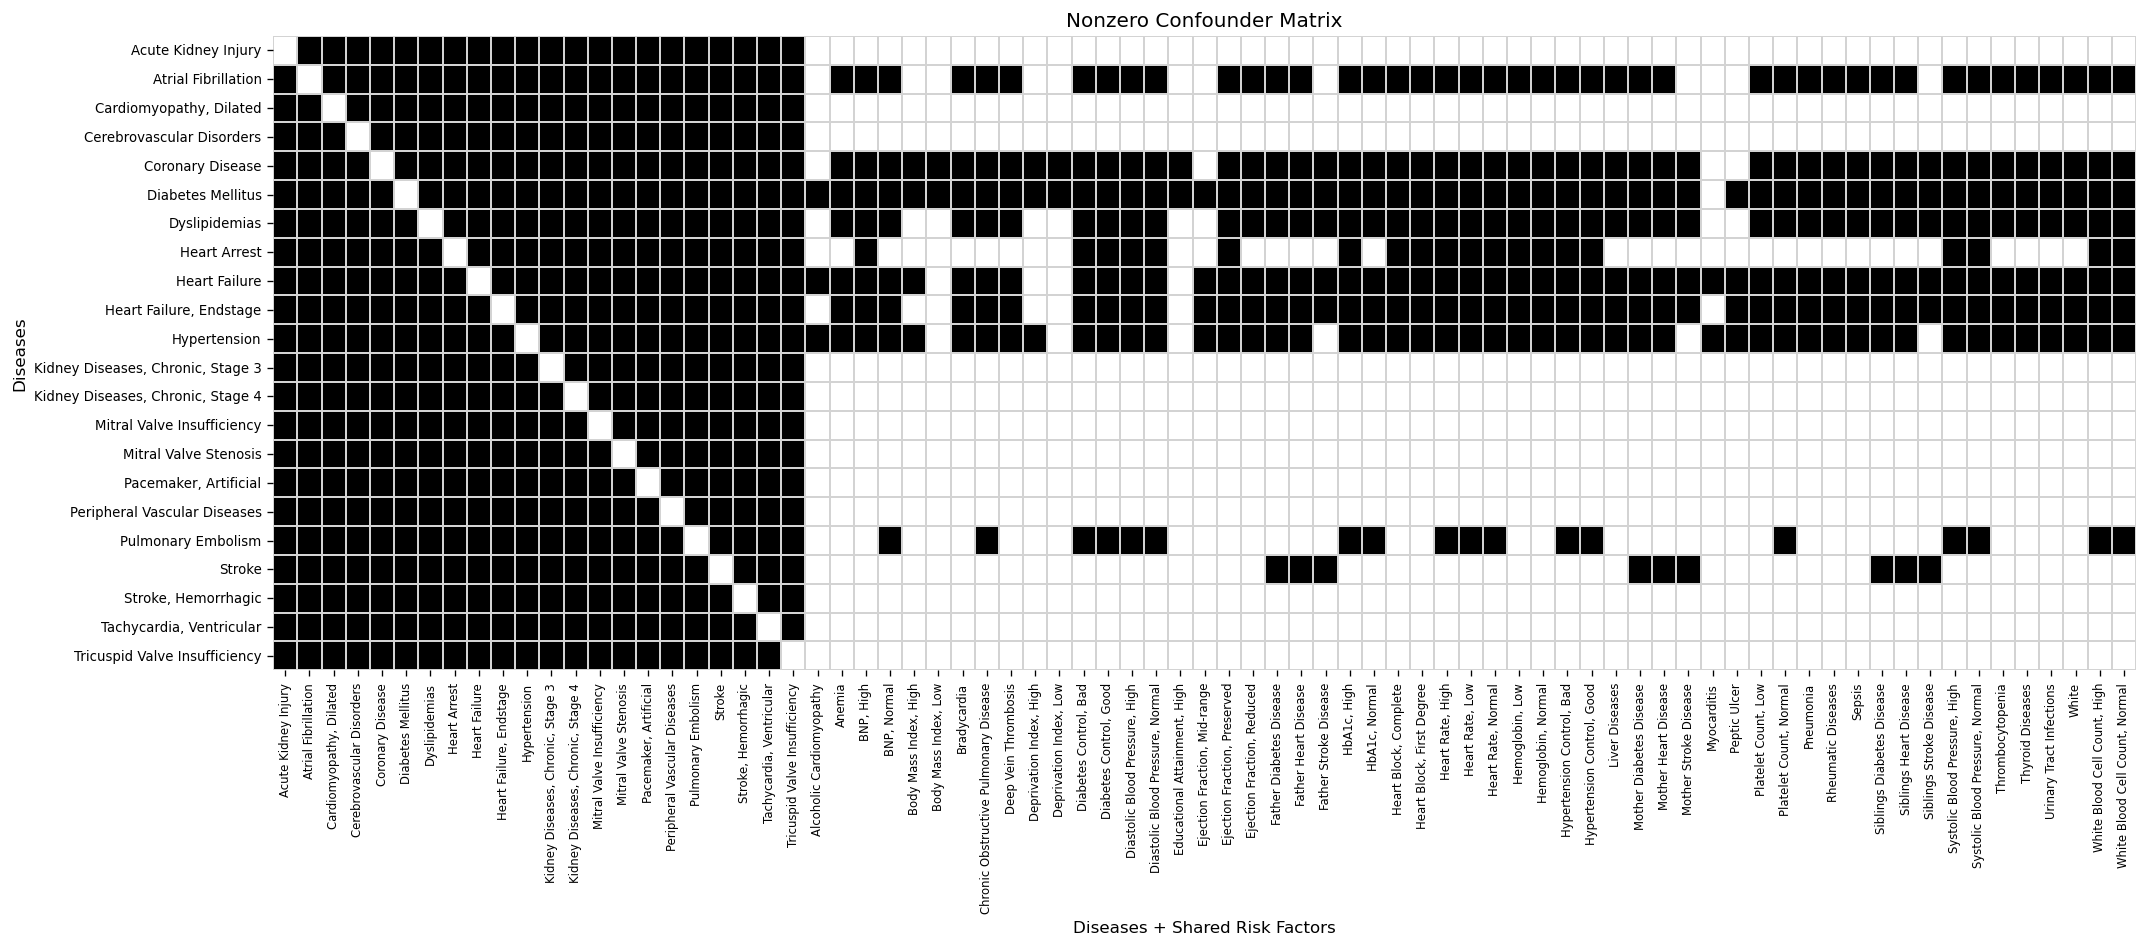

In [31]:
nonzero_cols = pair_rf_df.columns[pair_rf_df.sum(axis=0) > 0]
pair_rf_df_nonzero = pair_rf_df[nonzero_cols]

plt.figure(figsize=(18, 8))

sns.heatmap(
    pair_rf_df_nonzero,
    cmap="Greys",
    cbar=False,
    linewidths=0.2,
    linecolor="lightgray"
)

plt.xlabel("Diseases + Shared Risk Factors")
plt.ylabel("Diseases")
plt.title("Nonzero Confounder Matrix")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR,"confounder_matrix_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

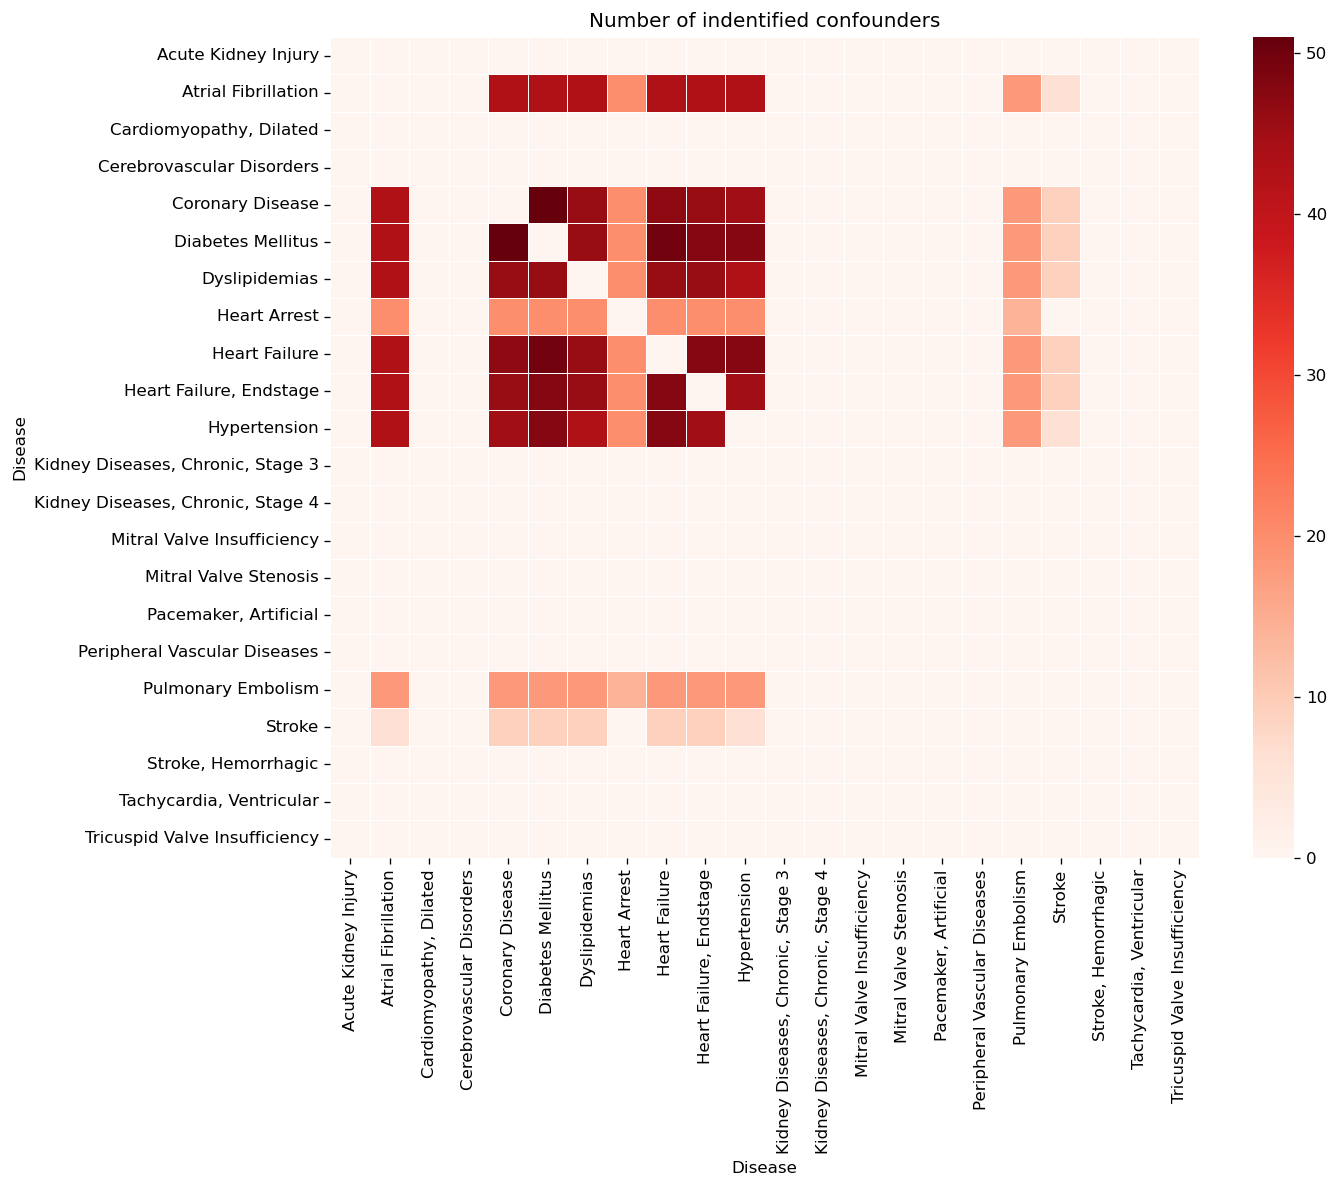

In [32]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    shared_rf_matrix,
    cmap="Reds",
    annot=False,          # remove numbers inside cells
    linewidths=0.5,
    linecolor="white",
    cbar=True             # show colorbar legend
)

plt.title("Number of indentified confounders")
plt.xlabel("Disease")
plt.ylabel("Disease")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

# Save figure
plt.savefig(
    os.path.join(OUTPUT_PLOTS_DIR,"shared_risk_factor_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
# Prepare the correct input format for the GGM 
n_rows, n_cols = pair_rf_df.shape
if n_rows < n_cols:
    rows_to_add = n_cols - n_rows
    ones_block = pd.DataFrame(
        np.ones((rows_to_add, n_cols)),
        columns=pair_rf_df.columns
    )
    pair_rf_df = pd.concat([pair_rf_df, ones_block], ignore_index=True)
np.fill_diagonal(pair_rf_df.values, 0)
pair_rf_df.to_csv(os.path.join(OUTPUT_RES_DIR,"GGM_prior_clinical_knowledge_input.csv"), index=False)